In [ ]:
#Load the cleaned dataset

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent
data_path = PROJECT_ROOT / "data" / "processed" / "sales_cleaned.csv"

print("Dataset exists:", data_path.exists())

df = pd.read_csv(data_path, parse_dates=["InvoiceDate"])

print("Dataset shape:", df.shape)
display(df.head())


Dataset exists: True
Dataset shape: (524878, 9)


C:\Users\prais\AppData\Local\Temp\ipykernel_19836\3343846968.py:12: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_path, parse_dates=["InvoiceDate"])


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [ ]:
#Verify the columns and customer data

In [2]:

print("Columns:")
print(df.columns.tolist())

print("\nMissing values:")
display(df.isnull().sum())

print("\nUnique customers:", df["CustomerID"].nunique())
print("Unique invoices:", df["InvoiceNo"].nunique())

print("\nDate range:")
print(df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

print("\nNon-positive quantities:", (df["Quantity"] <= 0).sum())
print("Non-positive prices:", (df["UnitPrice"] <= 0).sum())


Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']

Missing values:


InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
dtype: int64


Unique customers: 4338
Unique invoices: 19962

Date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00

Non-positive quantities: 0
Non-positive prices: 0


In [ ]:
#Prepare customer-level transaction data

In [3]:

customer_df = df.dropna(subset=["CustomerID"]).copy()

customer_df["CustomerID"] = customer_df["CustomerID"].astype("int64")
customer_df["InvoiceDate"] = pd.to_datetime(customer_df["InvoiceDate"])
customer_df["Revenue"] = (
    customer_df["Quantity"] * customer_df["UnitPrice"]
)

print("Transactions available for customer analysis:", len(customer_df))
print("Customers available:", customer_df["CustomerID"].nunique())

display(customer_df.head())


Transactions available for customer analysis: 392692
Customers available: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [ ]:
#Calculate customer purchase metrics

In [4]:

customer_metrics = (
    customer_df.groupby("CustomerID")
    .agg(
        total_spend=("Revenue", "sum"),
        total_orders=("InvoiceNo", "nunique"),
        total_units=("Quantity", "sum"),
        first_purchase=("InvoiceDate", "min"),
        last_purchase=("InvoiceDate", "max"),
    )
    .reset_index()
)

customer_metrics["average_order_value"] = (
    customer_metrics["total_spend"] /
    customer_metrics["total_orders"]
)

customer_metrics = customer_metrics.sort_values(
    "total_spend", ascending=False
)

display(customer_metrics.head(10))


,CustomerID,total_spend,total_orders,total_units,first_purchase,last_purchase,average_order_value
1689,14646,280206.02,73,196915,2010-12-20 10:09:00,2011-12-08 12:12:00,3838.438630
4201,18102,259657.30,60,64124,2010-12-07 16:42:00,2011-12-09 11:50:00,4327.621667
3728,17450,194390.79,46,69973,2010-12-07 09:23:00,2011-12-01 13:29:00,4225.886739
3008,16446,168472.50,2,80997,2011-05-18 09:52:00,2011-12-09 09:15:00,84236.250000
1879,14911,143711.17,201,80240,2010-12-01 14:05:00,2011-12-08 15:54:00,714.980945
55,12415,124914.53,21,77374,2011-01-06 11:12:00,2011-11-15 14:22:00,5948.310952
1333,14156,117210.08,55,57768,2010-12-03 11:48:00,2011-11-30 10:54:00,2131.092364
3771,17511,91062.38,31,64549,2010-12-01 10:19:00,2011-12-07 10:12:00,2937.496129
2702,16029,80850.84,63,40108,2010-12-01 09:57:00,2011-11-01 10:27:00,1283.346667
0,12346,77183.60,1,74215,2011-01-18 10:01:00,2011-01-18 10:01:00,77183.600000


In [ ]:
# Calculate RFM metrics
#RFM stands for:
#- Recency (R): How recently a customer purchased.
#- Frequency (F): How many distinct invoices a customer has.
#- Monetary (M): How much a customer spent in the retained transactions

In [5]:

# Use one day after the last transaction as the reference date
snapshot_date = customer_df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = (
    customer_df.groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum"),
    )
    .reset_index()
)

print("Reference date:", snapshot_date.date())
print("Customers scored:", len(rfm))
display(rfm.head(10))


Reference date: 2011-12-10
Customers scored: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346,325,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,18,1,1757.55
4,12350,310,1,334.40
5,12352,36,8,2506.04
6,12353,204,1,89.00
7,12354,232,1,1079.40
8,12355,214,1,459.40
9,12356,22,3,2811.43


In [ ]:
#Inspect the RFM distributions

,Recency,Frequency,Monetary
count,4338.000000,4338.000000,4338.000000
mean,92.059474,4.272245,2048.688081
std,100.012264,7.697975,8985.230220
min,0.000000,1.000000,3.750000
25%,17.000000,1.000000,306.482500
50%,50.000000,2.000000,668.570000
75%,141.750000,5.000000,1660.597500
max,373.000000,209.000000,280206.020000


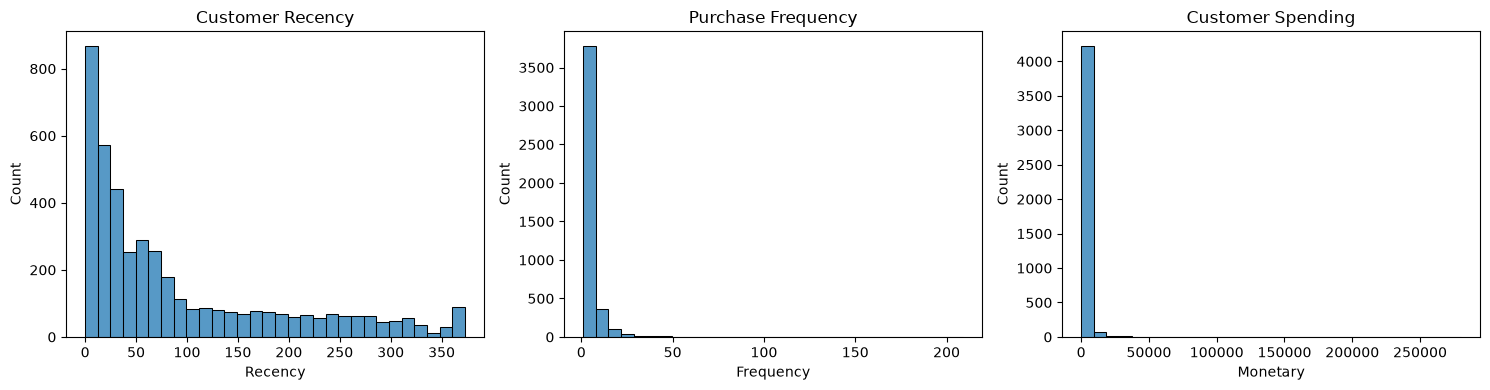

In [6]:

display(rfm[["Recency", "Frequency", "Monetary"]].describe())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(data=rfm, x="Recency", bins=30, ax=axes[0])
axes[0].set_title("Customer Recency")

sns.histplot(data=rfm, x="Frequency", bins=30, ax=axes[1])
axes[1].set_title("Purchase Frequency")

sns.histplot(data=rfm, x="Monetary", bins=30, ax=axes[2])
axes[2].set_title("Customer Spending")

plt.tight_layout()
plt.show()


In [ ]:
#Assign RFM scores

In [7]:

# Rank values first to handle ties more reliably
rfm["R_score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

rfm["F_score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["M_score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

rfm["RFM_score"] = (
    rfm["R_score"].astype(str)
    + rfm["F_score"].astype(str)
    + rfm["M_score"].astype(str)
)

display(rfm.head(10))


,CustomerID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score
0,12346,325,1,77183.60,1,1,5,115
1,12347,2,7,4310.00,5,5,5,555
2,12348,75,4,1797.24,2,4,4,244
3,12349,18,1,1757.55,4,1,4,414
4,12350,310,1,334.40,1,1,2,112
5,12352,36,8,2506.04,3,5,5,355
6,12353,204,1,89.00,1,1,1,111
7,12354,232,1,1079.40,1,1,4,114
8,12355,214,1,459.40,1,1,2,112
9,12356,22,3,2811.43,4,3,5,435


In [ ]:
#Create understandable customer segments

In [8]:

def assign_segment(row):
    if row["R_score"] >= 4 and row["F_score"] >= 4 and row["M_score"] >= 4:
        return "High-Value Active"
    elif row["R_score"] >= 3 and row["F_score"] >= 3:
        return "Regular Customers"
    elif row["R_score"] <= 2 and row["F_score"] >= 3:
        return "At-Risk Previously Frequent"
    elif row["R_score"] >= 4 and row["F_score"] <= 2:
        return "Recent New/Occasional"
    else:
        return "Other Customers"

rfm["Segment"] = rfm.apply(assign_segment, axis=1)

segment_summary = (
    rfm.groupby("Segment", observed=True)
    .agg(
        Customers=("CustomerID", "count"),
        Average_Recency=("Recency", "mean"),
        Average_Frequency=("Frequency", "mean"),
        Average_Monetary=("Monetary", "mean"),
        Total_Monetary=("Monetary", "sum"),
    )
    .sort_values("Customers", ascending=False)
    .reset_index()
)

display(segment_summary.round(2))


,Segment,Customers,Average_Recency,Average_Frequency,Average_Monetary,Total_Monetary
0,Other Customers,1425,175.76,1.12,483.43,688892.88
1,Regular Customers,998,32.79,3.74,1494.08,1491094.73
2,High-Value Active,942,11.97,11.21,6097.72,5744047.59
3,At-Risk Previously Frequent,663,149.94,3.42,1247.99,827416.57
4,Recent New/Occasional,310,17.67,1.25,437.93,135757.12


In [ ]:
#Visualize customer segments

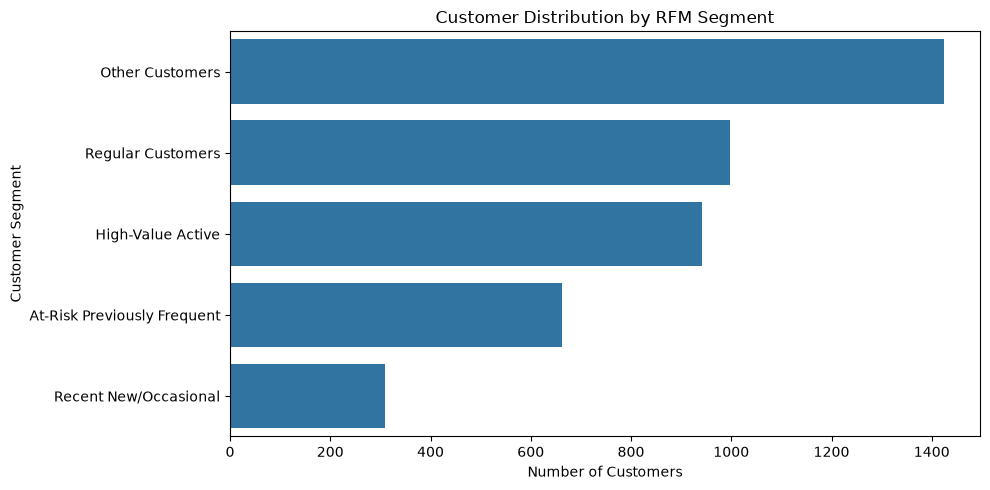

In [9]:

plt.figure(figsize=(10, 5))

segment_counts = (
    rfm["Segment"]
    .value_counts()
    .sort_values(ascending=False)
)

sns.barplot(x=segment_counts.values, y=segment_counts.index)

plt.title("Customer Distribution by RFM Segment")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()


In [ ]:
#Revenue contribution by segment

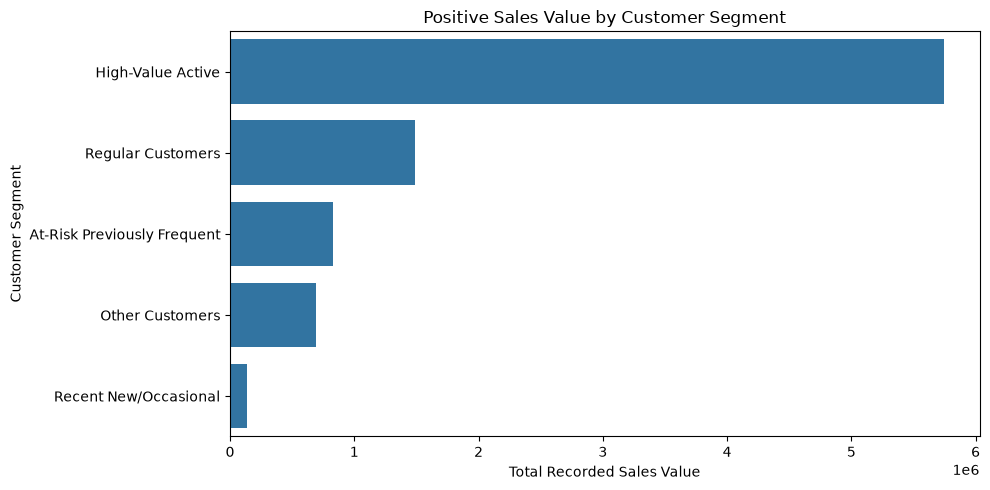

In [10]:

segment_revenue = (
    rfm.groupby("Segment", observed=True)["Monetary"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
sns.barplot(x=segment_revenue.values, y=segment_revenue.index)

plt.title("Positive Sales Value by Customer Segment")
plt.xlabel("Total Recorded Sales Value")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()


In [ ]:
#Frequency versus monetary value

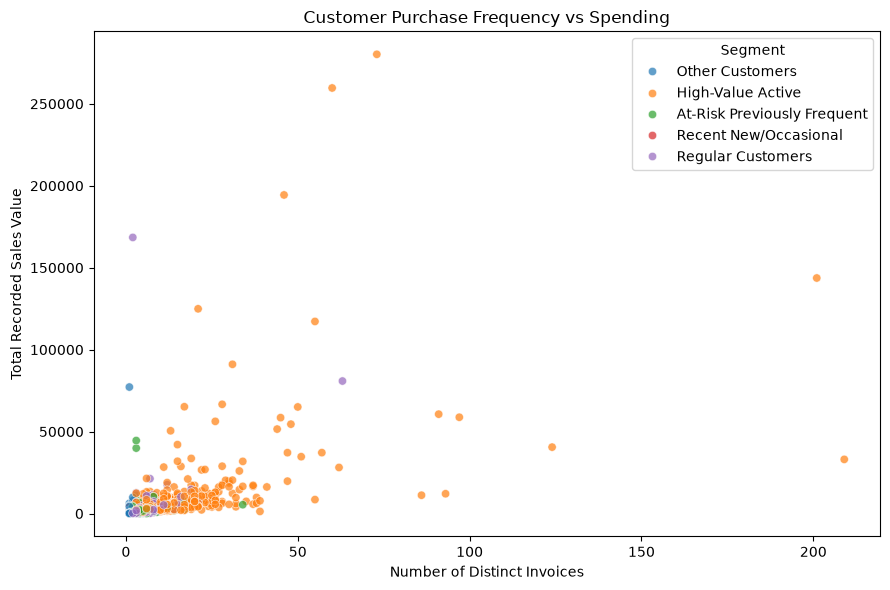

In [11]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Segment",
    alpha=0.7
)

plt.title("Customer Purchase Frequency vs Spending")
plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Total Recorded Sales Value")
plt.tight_layout()
plt.show()


In [ ]:
#Save the results

In [12]:

from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
output_dir = PROJECT_ROOT / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

rfm.to_csv(output_dir / "customer_rfm_segments.csv", index=False)
segment_summary.to_csv(
    output_dir / "segment_summary.csv",
    index=False
)

print("Saved customer RFM segments.")
print("Saved segment summary.")
print("RFM file exists:",
      (output_dir / "customer_rfm_segments.csv").exists())
print("Summary file exists:",
      (output_dir / "segment_summary.csv").exists())


Saved customer RFM segments.
Saved segment summary.
RFM file exists: True
Summary file exists: True


In [ ]:
#Create the SQLite database

In [13]:

import sqlite3
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd().parent

csv_path = PROJECT_ROOT / "data" / "processed" / "sales_cleaned.csv"
db_path = PROJECT_ROOT / "data" / "processed" / "customer_analysis.db"

df = pd.read_csv(csv_path)

with sqlite3.connect(db_path) as conn:
    df.to_sql("sales", conn, if_exists="replace", index=False)

print("Database created:", db_path.exists())


C:\Users\prais\AppData\Local\Temp\ipykernel_19836\1293044354.py:10: DtypeWarning: Columns (0: InvoiceNo) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


Database created: True


In [ ]:
#Test the SQL queries

In [14]:

with sqlite3.connect(db_path) as conn:
    query = """
    SELECT
        CustomerID,
        ROUND(SUM(Revenue), 2) AS total_spend,
        COUNT(DISTINCT InvoiceNo) AS total_orders
    FROM sales
    WHERE CustomerID IS NOT NULL
    GROUP BY CustomerID
    ORDER BY total_spend DESC
    LIMIT 10;
    """

    top_customers = pd.read_sql_query(query, conn)

display(top_customers)


,CustomerID,total_spend,total_orders
0,14646.0,280206.02,73
1,18102.0,259657.30,60
2,17450.0,194390.79,46
3,16446.0,168472.50,2
4,14911.0,143711.17,201
5,12415.0,124914.53,21
6,14156.0,117210.08,55
7,17511.0,91062.38,31
8,16029.0,80850.84,63
9,12346.0,77183.60,1
